# Лабораторная работа № 4 — Стационарность временного ряда

**Цель:** исследовать стационарность, применить статистические тесты и подобрать порядок дифференцирования.  
**Данные:** потребление электроэнергии за 2007 год из [UCI Individual Household Electric Power Consumption](https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption) — тот же датасет, что в лабораторных № 1–2. Почасовые значения агрегируем до дневных; сезонный период — 7 дней.

## 1. Загрузка данных

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss
from arch.unitroot import PhillipsPerron, DFGLS
from pmdarima.arima import ndiffs, nsdiffs

url = (
    "https://archive.ics.uci.edu/static/public/235/"
    "individual+household+electric+power+consumption.zip"
)
df = pd.read_csv(
    url, compression="zip", sep=";",
    usecols=["Date", "Time", "Global_active_power"], na_values=["?"],
)
df["timestamp"] = pd.to_datetime(
    df["Date"] + " " + df["Time"], format="%d/%m/%Y %H:%M:%S"
)
df["Global_active_power"] = pd.to_numeric(df["Global_active_power"], errors="coerce")

hourly = (df.sort_values("timestamp").drop_duplicates("timestamp")
          .set_index("timestamp")["Global_active_power"]
          .loc["2007"].resample("h").mean().asfreq("h"))
missing = int(hourly.isna().sum())
hourly = hourly.interpolate(method="time", limit_direction="both")
series = hourly.resample("D").mean().rename("power_kw")

print(f"2007 год: {len(series)} дней; заполнено {missing} пропущенных часов")

2007 год: 365 дней; заполнено 62 пропущенных часов


## 2. Исходный ряд, ACF и PACF

Проверяем тренд и недельную сезонность (`s = 7`).

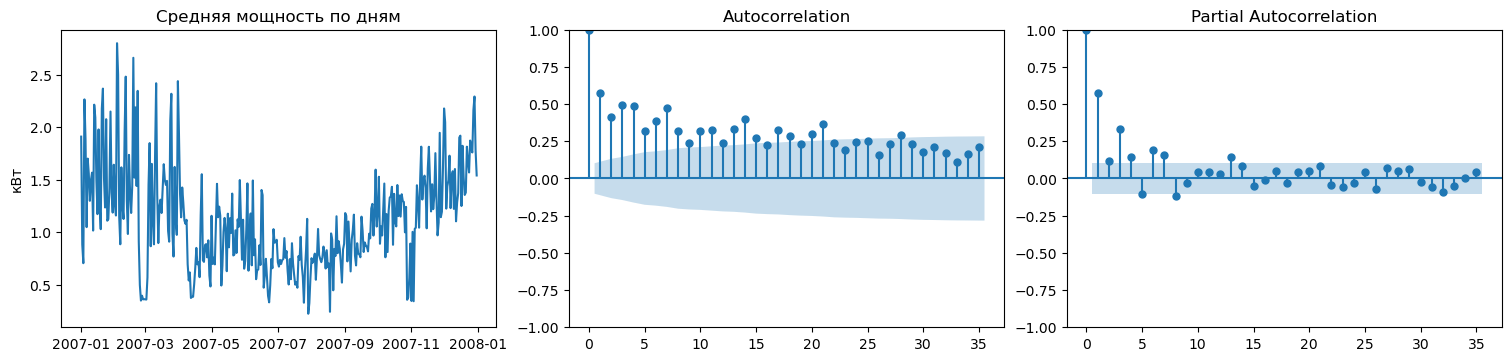

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5), constrained_layout=True)
ax[0].plot(series)
ax[0].set(title="Средняя мощность по дням", ylabel="кВт")
plot_acf(series, lags=35, ax=ax[1])
plot_pacf(series, lags=35, ax=ax[2], method="ywm")
plt.show()

## 3. Тесты стационарности

ADF, PP и DF-GLS: **H₀ — единичный корень**. KPSS: **H₀ — стационарность**. Порог `p = 0.05`.

In [21]:
import warnings
from statsmodels.tools.sm_exceptions import InterpolationWarning

def test_stationarity(x):
    x = x.dropna()

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", InterpolationWarning)

        return {
            "ADF": adfuller(x, autolag="AIC", result_object=True).pvalue,
            "PP": PhillipsPerron(x, trend="c").pvalue,
            "KPSS": kpss(
                x,
                regression="c",
                nlags="auto",
                result_object=True
            ).pvalue,
            "DF-GLS": DFGLS(x, trend="c").pvalue,
        }

results = {"Исходный": test_stationarity(series)}
pd.DataFrame(results).T.round(4)

,ADF,DF-GLS,KPSS,PP
Исходный,0.3109,0.3443,0.0176,0.0


## 4. Первые и сезонные разности

Сравним первые разности (`d = 1`) и первые + недельные разности (`d = 1, D = 1, s = 7`).

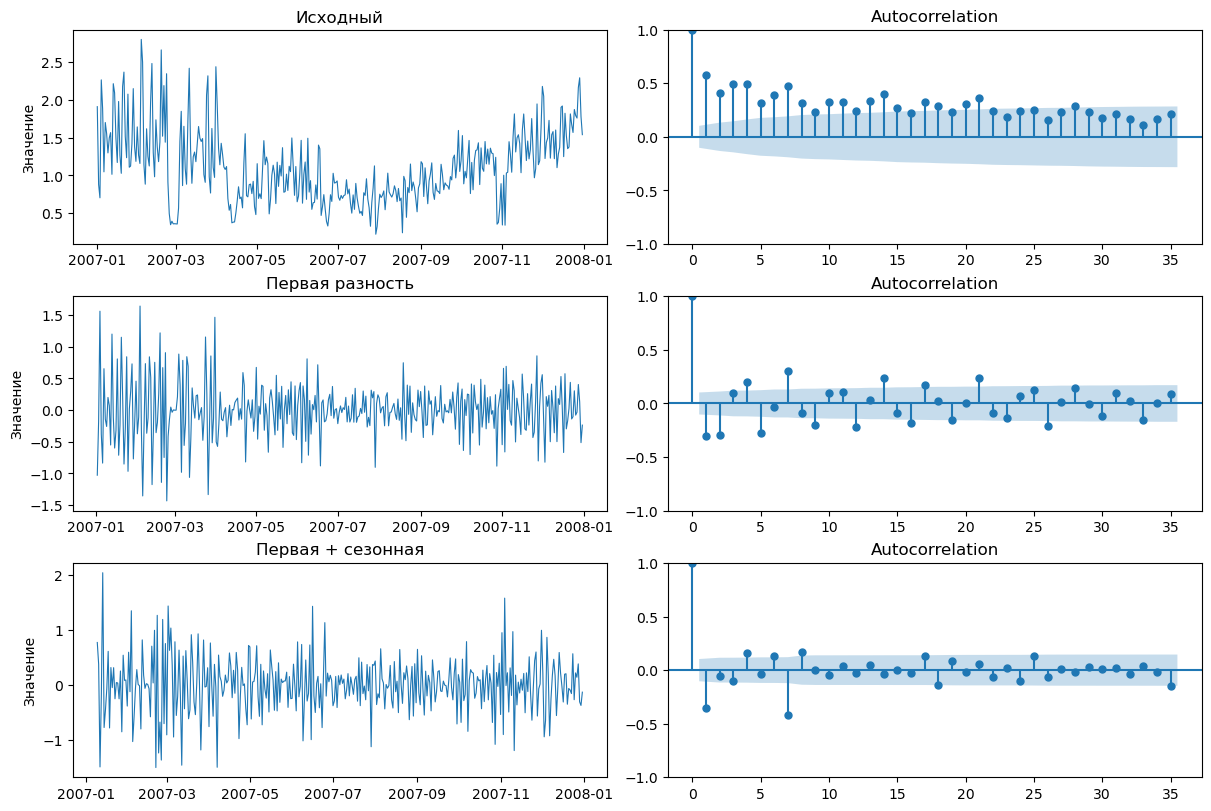

p-value (ADF, PP, DF-GLS: < 0.05; KPSS: >= 0.05)


,ADF,PP,KPSS,DF-GLS
Исходный,0.3109,0.0,0.0176,0.3443
Первая разность,0.0000,0.0,0.1000,0.5488
Первая + сезонная,0.0000,0.0,0.1000,0.5519


In [22]:
diff1 = series.diff().dropna()
diff1_seasonal = diff1.diff(7).dropna()

candidates = {
    "Исходный": series,
    "Первая разность": diff1,
    "Первая + сезонная": diff1_seasonal,
}

fig, ax = plt.subplots(3, 2, figsize=(12, 8), constrained_layout=True)
for row, (name, values) in enumerate(candidates.items()):
    ax[row, 0].plot(values, lw=0.8)
    ax[row, 0].set(title=name, ylabel="Значение")
    plot_acf(values, lags=35, ax=ax[row, 1])
plt.show()

for name, values in list(candidates.items())[1:]:
    results[name] = test_stationarity(values)

test_table = pd.DataFrame(results).T
print("p-value (ADF, PP, DF-GLS: < 0.05; KPSS: >= 0.05)")
display(test_table.round(4))

## 5. Автоматический подбор d и D

Сравним результаты тестов с рекомендациями `ndiffs()` и `nsdiffs()` для недельного периода.

In [27]:
auto_d = ndiffs(series, test="kpss", max_d=2)
auto_D = nsdiffs(series, m=7, test="ocsb", max_D=1)
print(f"ndiffs: d = {auto_d}; nsdiffs: D = {auto_D}")

# Согласованный вывод: три теста отвергают единичный корень,
# KPSS не отвергает стационарность.
passes = (
    (test_table[["ADF", "PP", "DF-GLS"]] < 0.05).all(axis=1)
    & (test_table["KPSS"] >= 0.05)
)
comparison = pd.DataFrame({
    "d": [0, 1, 1],
    "D": [0, 0, 1],
    "Тесты согласны": passes.values,
}, index=test_table.index)
display(comparison)

if passes.any():
    best = passes[passes].index[0]
    manual_d = int(comparison.loc[best, "d"])
    manual_D = int(comparison.loc[best, "D"])
    print(f"Первый вариант с согласованными тестами: {best} (d={manual_d}, D={manual_D})")
else:
    print("Тесты не дали согласованного ответа: нужен вывод с учётом графиков и ACF.")

ndiffs: d = 1; nsdiffs: D = 0


,d,D,Тесты согласны
Исходный,0,0,False
Первая разность,1,0,False
Первая + сезонная,1,1,False


Тесты не дали согласованного ответа: нужен вывод с учётом графиков и ACF.


In [30]:
acf_weekly = {name: series_.autocorr(lag=7) for name, series_ in candidates.items()}
print("ACF(7) по вариантам:")
print(pd.Series(acf_weekly).round(3).to_string())
print(f"Автоматически: d={auto_d}, D={auto_D}; сезонный период s=7")
if passes.any():
    print(f"По согласованию тестов: d={manual_d}, D={manual_D}")
else:
    print("Согласия четырёх тестов нет — интерпретируем таблицу и ACF вручную.")

ACF(7) по вариантам:
Исходный             0.499
Первая разность      0.312
Первая + сезонная   -0.443
Автоматически: d=1, D=0; сезонный период s=7
Согласия четырёх тестов нет — интерпретируем таблицу и ACF вручную.


## 6. Выводы

1. По ACF и PACF оцениваем зависимость между наблюдениями и наличие недельной сезонности.
2. Таблица `p-value` показывает, какие преобразования подтверждаются тестами ADF, PP, KPSS и DF-GLS. При расхождении тестов учитываем графики и возможные сдвиги уровня.
3. Сравниваем исходный ряд, первые разности и первые + недельные разности. Выбираем **минимальное** достаточное преобразование, избегая избыточного дифференцирования.
4. Сопоставляем ручной выбор `d` и `D` с рекомендациями `ndiffs()` и `nsdiffs()`. Различия допустимы: методы используют разные статистические критерии.
5. Логарифмирование / Box–Cox отдельно не применяем, если не установлено, что требуется стабилизировать дисперсию.

*После запуска уточнить заключение по фактическим значениям тестов и графикам.*